            LAB TASK 3: CREDIT CARD SEGMENTATION            

--- STAGE 1: DATASET LOADING ---
Files found in folder: ['CC GENERAL.csv']
Using file: /kaggle/input/datasets/abdulsami324243/credit-card-dataset/CC GENERAL.csv

Shape        : (8950, 18)
Columns      : ['CUST_ID', 'BALANCE', 'BALANCE_FREQUENCY', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'PURCHASES_FREQUENCY', 'ONEOFF_PURCHASES_FREQUENCY', 'PURCHASES_INSTALLMENTS_FREQUENCY', 'CASH_ADVANCE_FREQUENCY', 'CASH_ADVANCE_TRX', 'PURCHASES_TRX', 'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT', 'TENURE']

First 5 rows:
  CUST_ID      BALANCE  BALANCE_FREQUENCY  PURCHASES  ONEOFF_PURCHASES  \
0  C10001    40.900749           0.818182      95.40              0.00   
1  C10002  3202.467416           0.909091       0.00              0.00   
2  C10003  2495.148862           1.000000     773.17            773.17   
3  C10004  1666.670542           0.636364    1499.00           1499.00   
4

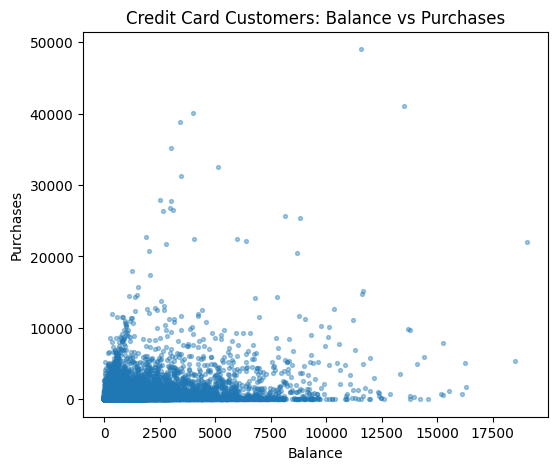


--- STAGE 3: PREPROCESSING ---
Missing values BEFORE filling:
BALANCE         0
PURCHASES       0
CASH_ADVANCE    0
CREDIT_LIMIT    1
PAYMENTS        0
dtype: int64

Missing values AFTER filling:
BALANCE         0
PURCHASES       0
CASH_ADVANCE    0
CREDIT_LIMIT    0
PAYMENTS        0
dtype: int64

Scaled feature matrix shape: (8950, 5)
First 3 scaled rows:
[[-0.73198937 -0.42489974 -0.46678555 -0.9603784  -0.52897879]
 [ 0.78696085 -0.46955188  2.60560451  0.68867844  0.81864213]
 [ 0.44713513 -0.10766823 -0.46678555  0.82609984 -0.38380474]]

--- STAGE 4: TRAINING (K-MEANS, K=4) ---
K-Means fitted with K = 4
Final inertia          : 21904.63

--- STAGE 5: TESTING (ASSIGN CLUSTERS) ---
Cluster sizes:
Cluster
0    2092
1    5991
2     788
3      79
Name: count, dtype: int64

--- STAGE 6: VALIDATION ---
Silhouette Score (K=4): 0.404

Average behaviour per cluster:
         BALANCE  PURCHASES  CASH_ADVANCE  CREDIT_LIMIT  PAYMENTS
Cluster                                                  

In [1]:
# ============================================================
# LAB TASK 3: CREDIT CARD CUSTOMER SEGMENTATION
# Dataset path: /kaggle/input/datasets/abdulsami324243/credit-card-dataset
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


# ------------------------------------------------------------
# Pretty output helper
# ------------------------------------------------------------
def print_banner(title):
    width = 60
    print("=" * width)
    print(title.center(width))
    print("=" * width)


def print_stage(n, name):
    print(f"\n--- STAGE {n}: {name} ---")


# ------------------------------------------------------------
# STAGE 1 — DATASET LOADING
# ------------------------------------------------------------
print_banner("LAB TASK 3: CREDIT CARD SEGMENTATION")
print_stage(1, "DATASET LOADING")

DATA_DIR = "/kaggle/input/datasets/abdulsami324243/credit-card-dataset"

# Auto-detect the CSV file inside the folder (handles any filename)
csv_files = [f for f in os.listdir(DATA_DIR) if f.lower().endswith(".csv")]
print(f"Files found in folder: {csv_files}")

if not csv_files:
    raise FileNotFoundError(f"No CSV file found in {DATA_DIR}")

DATA_PATH = os.path.join(DATA_DIR, csv_files[0])
print(f"Using file: {DATA_PATH}")

df = pd.read_csv(DATA_PATH)

print(f"\nShape        : {df.shape}")
print(f"Columns      : {list(df.columns)}")
print("\nFirst 5 rows:")
print(df.head())

# Check missing values BEFORE preprocessing
print("\nMissing values per column (top 10):")
print(df.isnull().sum().sort_values(ascending=False).head(10))


# ------------------------------------------------------------
# STAGE 2 — VISUALIZATION
# ------------------------------------------------------------
print_stage(2, "VISUALIZATION")

plt.figure(figsize=(6, 5))
plt.scatter(df["BALANCE"], df["PURCHASES"], s=8, alpha=0.4)
plt.xlabel("Balance")
plt.ylabel("Purchases")
plt.title("Credit Card Customers: Balance vs Purchases")
plt.show()


# ------------------------------------------------------------
# STAGE 3 — PREPROCESSING
# ------------------------------------------------------------
print_stage(3, "PREPROCESSING")

feature_cols = ["BALANCE", "PURCHASES", "CASH_ADVANCE",
                "CREDIT_LIMIT", "PAYMENTS"]

# Handle missing values: fill with column median
print("Missing values BEFORE filling:")
print(df[feature_cols].isnull().sum())

df[feature_cols] = df[feature_cols].fillna(df[feature_cols].median())

print("\nMissing values AFTER filling:")
print(df[feature_cols].isnull().sum())

# Scale the features so no single column dominates the distance metric
X_scaled = StandardScaler().fit_transform(df[feature_cols].values)
print(f"\nScaled feature matrix shape: {X_scaled.shape}")
print("First 3 scaled rows:")
print(X_scaled[:3])


# ------------------------------------------------------------
# STAGE 4 — TRAINING
# ------------------------------------------------------------
print_stage(4, "TRAINING (K-MEANS, K=4)")

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
kmeans.fit(X_scaled)

print("K-Means fitted with K = 4")
print(f"Final inertia          : {kmeans.inertia_:.2f}")


# ------------------------------------------------------------
# STAGE 5 — TESTING (Assign clusters to every cardholder)
# ------------------------------------------------------------
print_stage(5, "TESTING (ASSIGN CLUSTERS)")

df["Cluster"] = kmeans.predict(X_scaled)

print("Cluster sizes:")
print(df["Cluster"].value_counts().sort_index())


# ------------------------------------------------------------
# STAGE 6 — VALIDATION
# ------------------------------------------------------------
print_stage(6, "VALIDATION")

# (a) Silhouette Score
score = silhouette_score(X_scaled, df["Cluster"])
print(f"Silhouette Score (K=4): {score:.3f}")

# (b) Inspect average behaviour of each cluster
print("\nAverage behaviour per cluster:")
cluster_means = df.groupby("Cluster")[feature_cols].mean()
print(cluster_means.round(2))

# (c) Short human-readable description of each cluster
print("\nCluster interpretations:")
for cid, row in cluster_means.iterrows():
    print(f"  Cluster {cid}: "
          f"Balance={row['BALANCE']:.0f}, "
          f"Purchases={row['PURCHASES']:.0f}, "
          f"CashAdvance={row['CASH_ADVANCE']:.0f}, "
          f"CreditLimit={row['CREDIT_LIMIT']:.0f}, "
          f"Payments={row['PAYMENTS']:.0f}")

print_banner("END OF LAB TASK 3")

In [2]:
# ============================================================
# TASK 3 — STAGE 1: DATASET LOADING
# ============================================================

import pandas as pd
import os

DATA_PATH = "/kaggle/input/datasets/abdulsami324243/credit-card-dataset/CC GENERAL.csv"

# Safety: verify the file exists; if not, search for it
if not os.path.exists(DATA_PATH):
    print("Path not found. Searching /kaggle/input for CC GENERAL.csv ...")
    for root, dirs, files in os.walk("/kaggle/input"):
        for f in files:
            if f.lower() == "cc general.csv":
                DATA_PATH = os.path.join(root, f)
                print("Found at:", DATA_PATH)

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print(df.head())

Shape: (8950, 18)
Columns: ['CUST_ID', 'BALANCE', 'BALANCE_FREQUENCY', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'PURCHASES_FREQUENCY', 'ONEOFF_PURCHASES_FREQUENCY', 'PURCHASES_INSTALLMENTS_FREQUENCY', 'CASH_ADVANCE_FREQUENCY', 'CASH_ADVANCE_TRX', 'PURCHASES_TRX', 'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT', 'TENURE']
  CUST_ID      BALANCE  BALANCE_FREQUENCY  PURCHASES  ONEOFF_PURCHASES  \
0  C10001    40.900749           0.818182      95.40              0.00   
1  C10002  3202.467416           0.909091       0.00              0.00   
2  C10003  2495.148862           1.000000     773.17            773.17   
3  C10004  1666.670542           0.636364    1499.00           1499.00   
4  C10005   817.714335           1.000000      16.00             16.00   

   INSTALLMENTS_PURCHASES  CASH_ADVANCE  PURCHASES_FREQUENCY  \
0                    95.4      0.000000             0.166667   
1                     0.0   6442.945483            

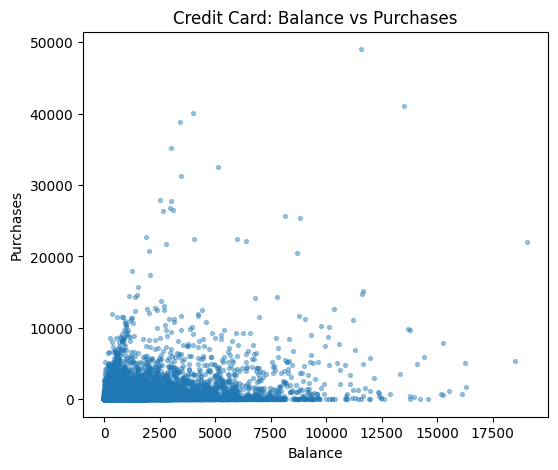

In [3]:
# ============================================================
# TASK 3 — STAGE 2: VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))
plt.scatter(df["BALANCE"], df["PURCHASES"], s=8, alpha=0.4)
plt.xlabel("Balance")
plt.ylabel("Purchases")
plt.title("Credit Card: Balance vs Purchases")
plt.show()

In [4]:
# ============================================================
# TASK 3 — STAGE 3: PREPROCESSING
# ============================================================

from sklearn.preprocessing import StandardScaler

feature_cols = ["BALANCE", "PURCHASES", "CASH_ADVANCE", "CREDIT_LIMIT", "PAYMENTS"]

# Check missing values BEFORE filling
print("Missing before fill:")
print(df[feature_cols].isna().sum())

# Fill missing values with the column median
df[feature_cols] = df[feature_cols].fillna(df[feature_cols].median())

# Verify no NaNs remain
print("\nMissing after fill:", df[feature_cols].isna().sum().sum())

# Scale
X_scaled = StandardScaler().fit_transform(df[feature_cols].values)
print("Scaled shape:", X_scaled.shape)

Missing before fill:
BALANCE         0
PURCHASES       0
CASH_ADVANCE    0
CREDIT_LIMIT    1
PAYMENTS        0
dtype: int64

Missing after fill: 0
Scaled shape: (8950, 5)


In [5]:
# ============================================================
# TASK 3 — STAGE 4: TRAINING
# ============================================================

from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
kmeans.fit(X_scaled)

print("Cluster centers (scaled space):")
print(kmeans.cluster_centers_)

Cluster centers (scaled space):
[[ 0.22838778  0.44890198 -0.15998554  0.95866483  0.26644874]
 [-0.37325166 -0.239325   -0.23607356 -0.5408489  -0.2986156 ]
 [ 2.09678436 -0.06923818  2.20875792  1.33658872  0.99428851]
 [ 1.38269011  6.93073771  0.16666558  2.28763735  5.68337404]]


In [6]:
# ============================================================
# TASK 3 — STAGE 5: TESTING
# ============================================================

df["Cluster"] = kmeans.predict(X_scaled)

print("Cluster sizes:")
print(df["Cluster"].value_counts().sort_index())

Cluster sizes:
Cluster
0    2092
1    5991
2     788
3      79
Name: count, dtype: int64


In [7]:
# ============================================================
# TASK 3 — STAGE 6: VALIDATION
# ============================================================

from sklearn.metrics import silhouette_score

print("Silhouette Score:", round(silhouette_score(X_scaled, df["Cluster"]), 3))

print("\nPer-cluster feature means:")
print(df.groupby("Cluster")[feature_cols].mean().round(2))

Silhouette Score: 0.404

Per-cluster feature means:
         BALANCE  PURCHASES  CASH_ADVANCE  CREDIT_LIMIT  PAYMENTS
Cluster                                                          
0        2038.79    1965.05        639.91       7983.98   2503.88
1         788.15     491.80        483.81       2526.76    868.74
2        5918.96     853.25       5607.61       9353.94   4609.40
3        4442.43   15810.83       1328.38      12817.72  18185.95
